# Notebook 94: does accepting an image have a lasting task benefit?

Status: **complete**. Saved live arrivals: **57,600/57,600**;
accepted updates: **6,771**. Planned candidates: **224**;
sampled: **224**; matured pairs: **224**;
valid pairs: **224**; scored after initialization: **159**.
The live report plots committed results; temporary branch work can be ahead of the last saved checkpoint.

## What changes from N93

This is a **shadow diagnostic**, not a new controlling policy. The live image model
starts from the same original warm parent and follows N93's constant admission
probability (11.8514%), health-driven LR/4 or LR/16, and existing numerical safety
and burst rules. The predictor never controls admission. The live path is checked
against saved N93 neutral at every arrival. N93's online arm was stopped at the
user's request at 41,183 arrivals/4,718 updates; its partial results are preserved.

The immediate N90/N93 target already approximates immediate accept-versus-skip
benefit, since a true skip leaves the encoder unchanged. Merely subtracting an
immediate baseline would add little. Here the new question is whether an update's
benefit **persists after 256 further arrivals**.

## Paired method and mathematical target

Select one candidate uniformly in each eligible 256-arrival block, independently
of admission and outcomes (224 planned, RNG 940026). Both accepted and rejected
live candidates can be sampled. At each eligible ordinary normal/caution origin,
save the complete model, AdamW state, module modes, CPU/CUDA RNG, controller,
health anchor, development backup scores and preceding health observations.

After the stream has actually processed the candidate and its next 256 arrivals,
create two independent copies of that origin state. **Accept branch:** apply one
singleton reconstruction update on the candidate. **Skip branch:** do nothing to
the model or optimizer. Continue both for the same next 256 incoming images,
with identical augmentation seeds and admission random draws, under the same
fixed neutral continuation rule. Their health and later decisions may diverge.
Neither branch trains an admission predictor. They are discarded after measurement;
the complete live state and RNG must remain unchanged.

Let S be balanced development soft error, measured with the existing fixed
development images and support-only refitted logistic readers. Lower is better.

$$b_{t,H} = S(\theta^{\mathrm{skip}}_{t+H})-S(\theta^{\mathrm{accept}}_{t+H}),\qquad H\in\{0,256\}.$$

Positive b means accepting helped; negative b means skipping helped. For example,
skip error 0.40 versus accept error 0.39 gives benefit +0.01. S averages
sigmoid((0.5-p_true)/0.05) over the balanced development queries and reader draws;
it is not raw accuracy, reconstruction loss or cross entropy.

## What the online learners predict

Two separate discounted ridge heads predict immediate benefit b_0 and delayed
benefit b_256 from the **same 19 pre-update features**: four health measurements,
their four preceding changes, five candidate loss/gradient/displacement signals,
two novelty signals, frozen J forecast, proposed learning rate, caution indicator
and preceding development soft error. Frozen J is information, not admission authority.

Both heads initialize on 64 valid matured pairs, fix their prefix scaling and clip
features to [-5,5], use ridge 10/intercept 0.1, and discount with a 64-pair half-life.
Both receive their target only at delayed maturity, after forecasting at the origin.
Their forecasts are logged before either can learn this pair. Unready forecasts
are excluded from predictive scoring. There is no prediction-driven image-model
update: the encoder continues to learn only through reconstruction gradients.

Primary comparison: chronological delayed-target MAE of delayed online ridge versus
zero and preceding-sample recent mean. Prefix-frozen ridge, the immediate head's
predictions on delayed targets, RMSE, direction, 30k+ results, effect sizes and
costs are secondary. Prefix samples are training-only; later samples are predicted
before learning and can subsequently train the online head.

Incoming image labels are unused, but development labels train the task-informed
controller. Final evaluation queries are used only to report the live trajectory.
This does not fix development-bank overfitting. Windows can overlap and all pairs
come from one reused stream: do not treat them as independent confirmations.
Accept/skip can change update budgets; this does not establish better selection
at equal compute or prove a controlling policy improves task accuracy.

## Chronological prediction results so far

| Forecast | Pairs | MAE | RMSE | Direction |
| --- | ---: | ---: | ---: | ---: |
| zero | 159 | 0.0001019 | 0.0001399 | 47.8% |
| recent mean | 159 | 0.0001143 | 0.0001481 | 47.8% |
| prefix frozen ridge | 159 | 0.0001818 | 0.0002142 | 54.7% |
| delayed online ridge | 159 | 0.0001124 | 0.0001479 | 55.3% |
| immediate online ridge | 159 | 0.0001257 | 0.0001617 | 43.4% |

Valid origins: 27 accepted live, 197 rejected live. Predictions remain observational; no controller efficacy conclusion follows from these errors.

Measured costs (seconds): live 1518.5, features 42.9, shadow 3178.6, readouts 54.0.


## N94 result interpretation (complete run)

**The delayed target is more useful than the immediate-target predictor in this
diagnostic; the delayed predictor does not pass the primary MAE comparisons on this history.**

Coverage: 57,600/57,600 arrivals, 6,771 live updates,
224 valid pairs and 159 chronological forecasts
made after initialization. Prefix samples are excluded. Numerical failures:
0. Original run interruption was a Windows live-HTML
sharing lock after a committed checkpoint; a separate reporting-only wrapper
resumed the unchanged frozen runner. This was not a model/numerical failure.

| Delayed-target forecast | MAE (x 10^-4; lower is better) | Direction |
| --- | ---: | ---: |
| zero | 1.019 | abstains |
| recent mean | 1.143 | 47.8% |
| prefix frozen ridge | 1.818 | 54.7% |
| delayed online ridge | 1.124 | 55.3% |
| immediate online ridge | 1.257 | 43.4% |

The delayed online head's MAE is **10.3% worse than zero**,
1.6% lower than recent mean and
10.6% lower than the immediate head on these delayed targets.
Its RMSE is 0.00014787 versus zero
0.00013991; sign accuracy alone is insufficient.
An always-beneficial sign forecast scores 52.2%
on this same sample. Zero supplies an error baseline but abstains on direction;
its thresholded sign must not be interpreted as a meaningful directional forecast.

**Immediate improvement is an imperfect proxy for lasting benefit.** Across the
scored pairs, observed immediate/delayed signs agree
60.4% of the time and Pearson
correlation is 0.298. This supports measuring
delayed outcomes; it does not establish that every disagreement is lasting harm,
or that the chosen 256-arrival horizon is optimal.

**There is a small, exploratory selection signal.** The delayed head's positive
forecasts identify 96 candidates
with mean observed benefit
0.00000849;
its remaining forecasts have mean benefit
-0.00001101.
These are development soft-error units, not accuracy percentage points. These
effects were measured in separate branches from the neutral trajectory: they
cannot be summed into a claimed new-policy accuracy gain.

**The 30k+ subset is secondary.** It contains 107 scored pairs. Delayed
online MAE is 0.00011234 versus
zero 0.00011189; directional accuracy is
53.3% versus
55.1% always-beneficial. Do not replace
the full primary result with the most favorable time interval.

The immediate-target head's MAE on its own immediate target is
0.00008368 versus its zero baseline
0.00006264. This sparse diagnostic retrains both heads on
paired candidates; its immediate head is not the original N90 head trained on
thousands of accepted updates.

The frozen-prefix model is much worse than the adaptive model, consistent with
distribution drift, but this comparison does not identify its cause. Any feature
clipping occurs in 3.1% of ready
samples. This diagnostic has only a small number of samples for 19 features,
one continuation draw per candidate, a fixed reused development bank, and
temporally dependent/possibly overlapping windows. It does not establish robust
generalization to fresh streams or untouched task queries.

All observed branch update-count differences: {'1': 224}.
Accept-versus-skip therefore compares an extra update, not equal-compute replacement.
The live image-model trajectory is neutral and is checked against saved N93;
unchanged live accuracy is expected and is not a failure of the shadow diagnostic.

## Exploratory feature audit (post hoc, not a primary result)

The following replays use the same 64-sample initialization, discounting and
strict maturity rules, without changing or rerunning image-model training.
State+context retains health/history, rate, caution and preceding development
error, while excluding candidate-specific features and candidate J forecast.
Candidate+context retains candidate features, candidate J forecast and context.
Context-only retains rate, caution and preceding development error.

| Feature design | Delayed MAE (x 10^-4) | Direction |
| --- | ---: | ---: |
| state_and_context | 1.025 | 51.6% |
| candidate_and_context | 1.141 | 52.8% |
| context_only | 1.032 | 54.1% |

These exploratory comparisons help distinguish knowing when any update is useful
from identifying a particularly useful image. They are not independent validation
and must not overwrite the registered primary comparisons.

**Recommendation:** retain the paired delayed target, but do not deploy this head
as a proven better admission policy. First confirm that its ranking separates
helpful/harmful candidates on a fresh chronological diagnostic with settings
locked, and verify transfer on untouched task queries. A larger/cleaner training
sample or a simpler candidate-versus-state comparison is a plausible next
development step; this run does not justify assuming that a larger model or
longer horizon will fix prediction. No further experiment is launched by this analysis.


## Measured immediate and delayed effects
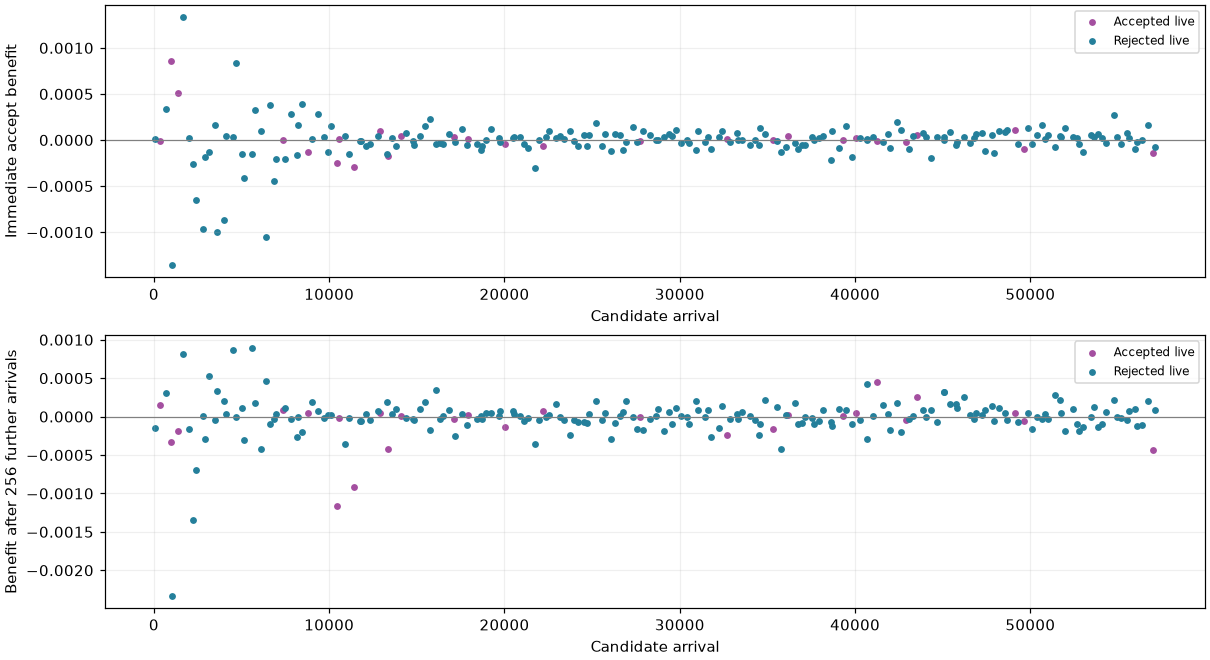

## Immediate persistence and chronological forecasts
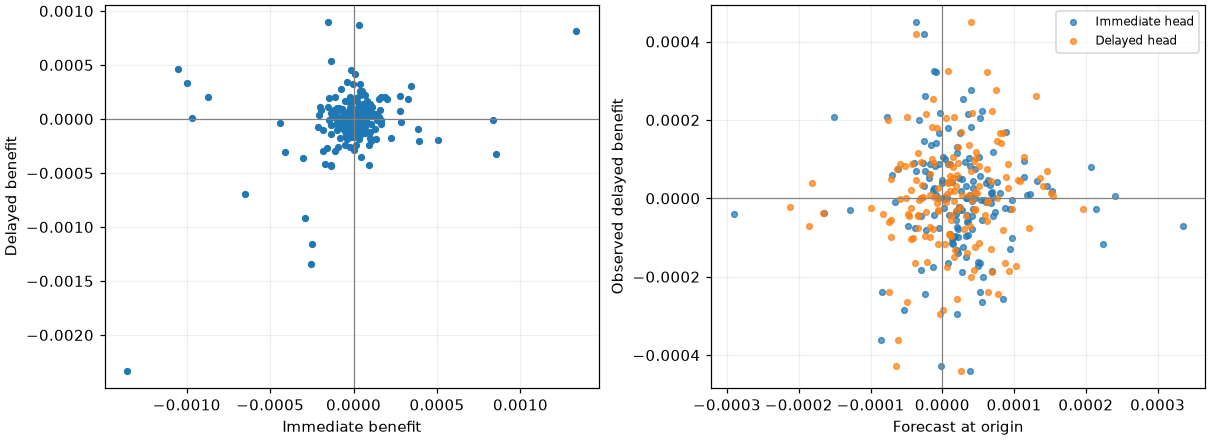

## Coverage and branch update budgets
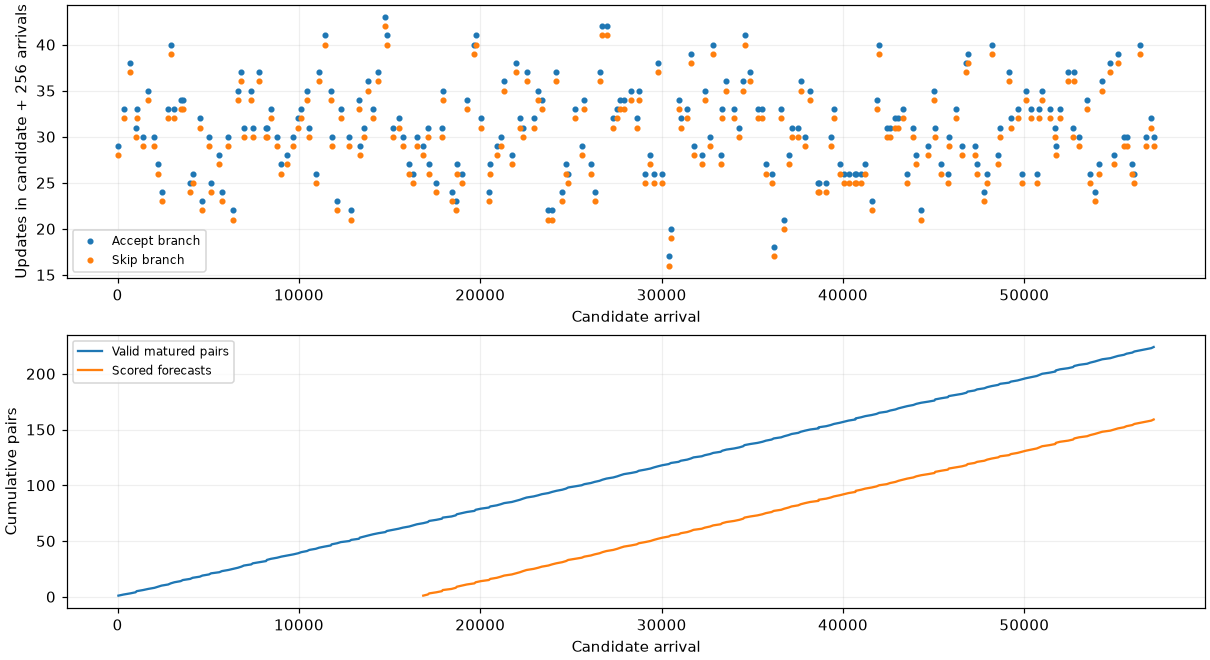

## Live image-model metrics (neutral identity check)
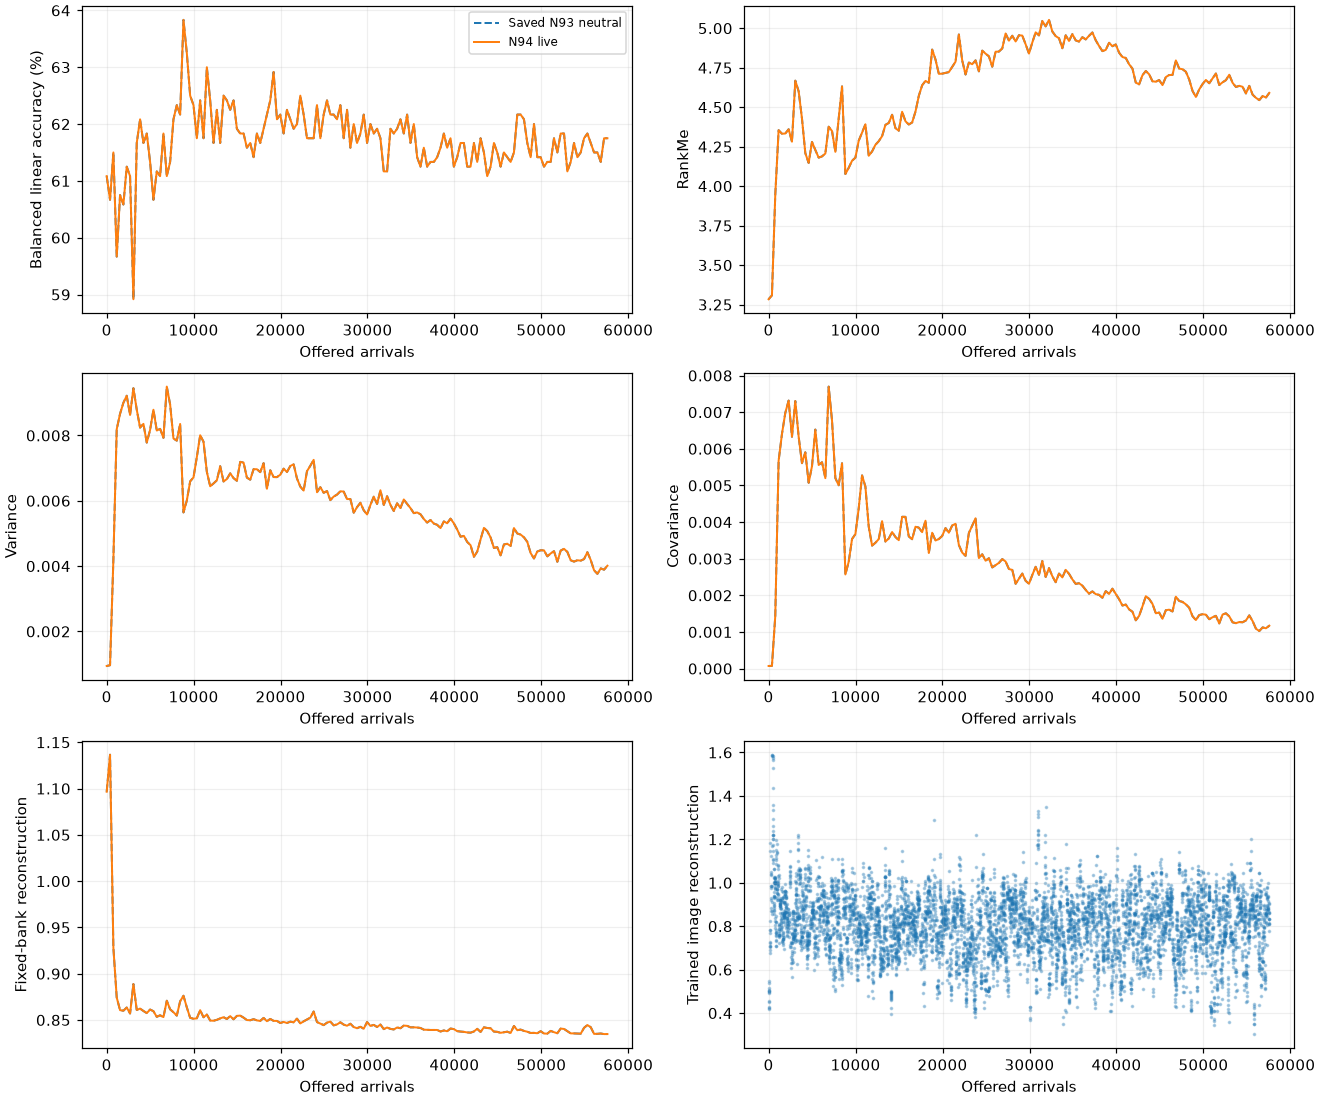